In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

In [2]:
data = load_iris()

df = pd.DataFrame(data.data, columns=data.feature_names)

y = data.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [4]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [5]:
print("Dataset Shape:", df.shape)

print("\nFlower Names:")
print(data.target_names)

Dataset Shape: (150, 4)

Flower Names:
['setosa' 'versicolor' 'virginica']


In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df)

In [7]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

In [8]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

pca_df.head()

,Principal Component 1,Principal Component 2
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835


In [9]:
print("Original Shape:", X_scaled.shape)

print("PCA Shape:", X_pca.shape)

Original Shape: (150, 4)
PCA Shape: (150, 2)


In [10]:
print("Explained Variance Ratio:")

print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")

print(pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[0.72962445 0.22850762]

Total Explained Variance:
0.9581320720000166


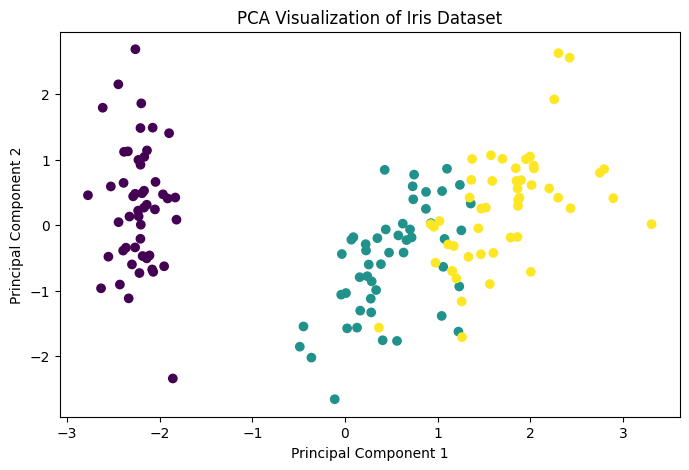

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Visualization of Iris Dataset")

plt.show()

In [12]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_pca)

pca_df["Cluster"] = clusters

pca_df.head()

c:\Users\hassa\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\hassa\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\hassa\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\hassa\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 966, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\hassa\AppData\Local\Programs\Python\Python310\lib\subp

,Principal Component 1,Principal Component 2,Cluster
0,-2.264703,0.480027,1
1,-2.080961,-0.674134,1
2,-2.364229,-0.341908,1
3,-2.299384,-0.597395,1
4,-2.389842,0.646835,1


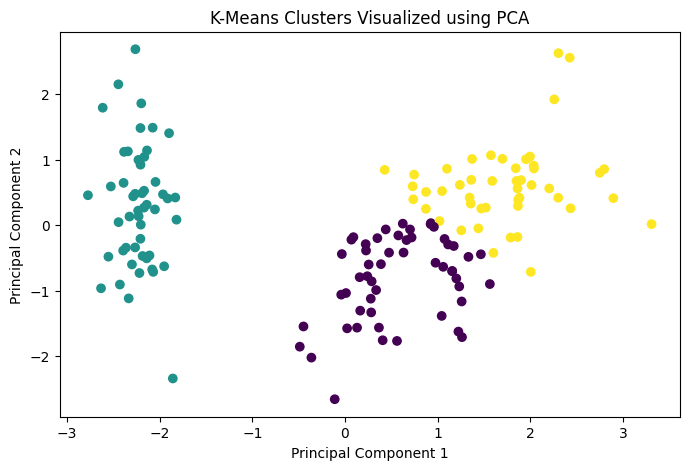

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("K-Means Clusters Visualized using PCA")

plt.show()

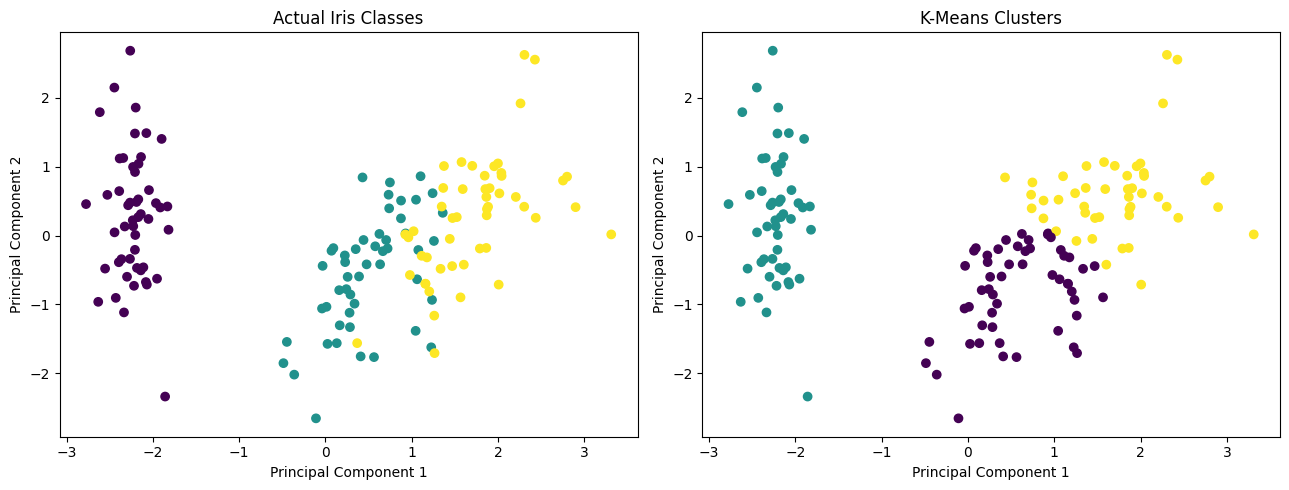

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis"
)

axes[0].set_title("Actual Iris Classes")

axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")


axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis"
)

axes[1].set_title("K-Means Clusters")

axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()

plt.show()

In [15]:
print("PCA Completed Successfully!")

print("Original Features:", X_scaled.shape[1])

print("Reduced Features:", X_pca.shape[1])

print("Total Explained Variance:",
      pca.explained_variance_ratio_.sum())

print("\nCluster Distribution:")
print(pca_df["Cluster"].value_counts())


PCA Completed Successfully!
Original Features: 4
Reduced Features: 2
Total Explained Variance: 0.9581320720000166

Cluster Distribution:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64
